<a href="https://colab.research.google.com/github/JoelPereira31/desafio-dio-deteccao-fraude-cartao/blob/main/deteccao_fraude_cartao.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
# Manipulação de dados e matemática básica
import pandas as pd
import numpy as np

# Gráficos
import matplotlib.pyplot as plt
import seaborn as sns

# Pré-processamento do Scikit-Learn
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

# Modelos de Machine Learning
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier

# Métricas de Avaliação
from sklearn.metrics import classification_report, confusion_matrix, precision_recall_curve

# Explicabilidade
import shap

print("Bibliotecas importadas com sucesso!")

Bibliotecas importadas com sucesso!


In [3]:
# Link alternativo, estável e direto para o dataset de fraude de cartão de crédito
url = "https://storage.googleapis.com/download.tensorflow.org/data/creditcard.csv"

# Carregando com o pandas
df = pd.read_csv(url)

# Vendo as 5 primeiras linhas para entender a cara dos dados
print(df.head())

# Vendo a proporção exata de fraudes (0 = Normal, 1 = Fraude)
print("\nProporção das classes (%):")
print(df['Class'].value_counts(normalize=True) * 100)

   Time        V1        V2        V3        V4        V5        V6        V7  \
0   0.0 -1.359807 -0.072781  2.536347  1.378155 -0.338321  0.462388  0.239599   
1   0.0  1.191857  0.266151  0.166480  0.448154  0.060018 -0.082361 -0.078803   
2   1.0 -1.358354 -1.340163  1.773209  0.379780 -0.503198  1.800499  0.791461   
3   1.0 -0.966272 -0.185226  1.792993 -0.863291 -0.010309  1.247203  0.237609   
4   2.0 -1.158233  0.877737  1.548718  0.403034 -0.407193  0.095921  0.592941   

         V8        V9  ...       V21       V22       V23       V24       V25  \
0  0.098698  0.363787  ... -0.018307  0.277838 -0.110474  0.066928  0.128539   
1  0.085102 -0.255425  ... -0.225775 -0.638672  0.101288 -0.339846  0.167170   
2  0.247676 -1.514654  ...  0.247998  0.771679  0.909412 -0.689281 -0.327642   
3  0.377436 -1.387024  ... -0.108300  0.005274 -0.190321 -1.175575  0.647376   
4 -0.270533  0.817739  ... -0.009431  0.798278 -0.137458  0.141267 -0.206010   

        V26       V27       V28 

In [4]:
# Criando uma cópia do DataFrame para trabalhar
df_model = df.copy()

# 1. Aplicando log no 'Amount' para suavizar valores muito altos (dinheiro varia muito)
df_model['Log_Amount'] = np.log1p(df_model['Amount'])

# Removendo a coluna 'Amount' original e a 'Time' (que não ajudam diretamente na detecção)
df_model = df_model.drop(['Time', 'Amount'], axis=1)

# 2. Separando as Features (X - variáveis de entrada) da Variável Alvo (y - se é fraude ou não)
X = df_model.drop('Class', axis=1)
y = df_model['Class']

# 3. Separando em Treino e Teste (stratify=y garante que os 0.17% de fraude existam tanto no treino quanto no teste)
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.3, random_state=42, stratify=y
)

# 4. Padronizando as variáveis numéricas
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("Dados preparados e divididos com sucesso!")
print(f"Tamanho do conjunto de treino: {X_train.shape}")
print(f"Tamanho do conjunto de teste: {X_test.shape}")

Dados preparados e divididos com sucesso!
Tamanho do conjunto de treino: (199364, 29)
Tamanho do conjunto de teste: (85443, 29)


In [5]:
# 1. Criando o modelo de Regressão Logística com pesos balanceados
lr_model = LogisticRegression(class_weight='balanced', random_state=42)

# 2. Treinando o modelo com os dados de treino
lr_model.fit(X_train_scaled, y_train)

# 3. Fazendo previsões nos dados de teste (que o modelo nunca viu)
y_pred = lr_model.predict(X_test_scaled)

# 4. Imprimindo o relatório de classificação completo
print("Relatório de Classificação (Regressão Logística):\n")
print(classification_report(y_test, y_pred))

Relatório de Classificação (Regressão Logística):

              precision    recall  f1-score   support

           0       1.00      0.98      0.99     85295
           1       0.06      0.88      0.12       148

    accuracy                           0.98     85443
   macro avg       0.53      0.93      0.55     85443
weighted avg       1.00      0.98      0.99     85443



In [6]:
# 1. Pegando as probabilidades da classe 1 (probabilidade de ser fraude)
y_prob = lr_model.predict_proba(X_test_scaled)[:, 1]

# 2. Vamos testar um limiar diferente, por exemplo, 0.7 (70% de certeza exigida)
novo_limiar = 0.7
y_pred_novo = (y_prob >= novo_limiar).astype(int)

print(f"Relatório de Classificação com Limiar de {novo_limiar}:\n")
print(classification_report(y_test, y_pred_novo))

Relatório de Classificação com Limiar de 0.7:

              precision    recall  f1-score   support

           0       1.00      0.99      0.99     85295
           1       0.12      0.85      0.21       148

    accuracy                           0.99     85443
   macro avg       0.56      0.92      0.60     85443
weighted avg       1.00      0.99      0.99     85443



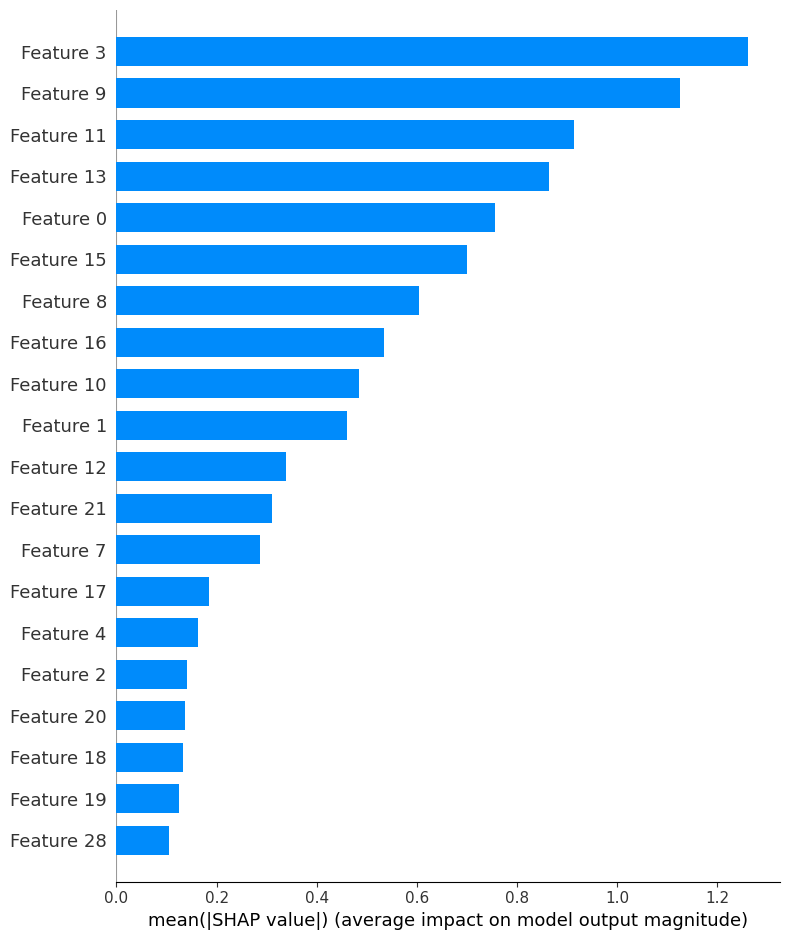

In [7]:
# O SHAP pode demorar um pouco se rodar na base inteira,
# então vamos usar uma amostra de 200 linhas do conjunto de teste para ser mais rápido
import shap

# Criando o explicador do SHAP para o modelo de Regressão Logística
explainer = shap.LinearExplainer(lr_model, X_train_scaled)
shap_values = explainer(X_test_scaled[:200])

# Gerando o gráfico de resumo (summary plot)
plt.figure(figsize=(10, 6))
shap.summary_plot(shap_values, X_test[:200], plot_type="bar")